# 05. Ask for data and tell the truth

Handle asynchronous requests, validate responses, and use TanStack Query to keep each owner’s records coherent.

**60 minutes including practice · Roots**

This is a **Python 3 notebook**. It contains the complete lesson, embedded vector illustrations, React Native examples for reading, and executable Python models. Python does not run React Native. Run the `.tsx` exercise in Expo using the workbook instructions. No cloud credentials or live services are needed for the notebook.

Run the cells from top to bottom. Change a control, make a prediction, then explain the result. If widgets are unavailable, edit a model's default arguments and rerun its cell.

If you have the complete course folder, [open the interactive guide](../index.html#lesson-05) or [read the exercise instructions](../exercises/README.md). These companion links are absent in a notebooks-only or single-lesson download; the notebook itself still runs independently.


## What you will be able to do

- You can explain network rejection, HTTP errors, invalid response data, and an empty success separately.
- You can build an owner-scoped query key and display cached data during a refresh.
- You can explain when a successful write should invalidate a query.

## Before you begin

You can distinguish local interaction state from server-owned records.

You can read async functions and a try/catch block.


In [1]:
from IPython.display import display, HTML, SVG
import json
import os
import inspect

# Widgets are optional. Without them, edit parameters and rerun the model cell.
try:
    if os.environ.get('PLANTOPEDIA_NO_WIDGETS') == '1':
        raise ImportError('Widget-free verification mode')
    import ipywidgets as widgets
except ImportError:
    widgets = None

def explore(function, **controls):
    if widgets is not None:
        display(widgets.interactive(function, **controls))
    else:
        print('Optional controls are unavailable. Edit the explorer function defaults and rerun this model cell.')
        defaults = {name: parameter.default for name, parameter in inspect.signature(function).parameters.items()}
        print('Using function defaults:', defaults)
        function()

print('Python teaching model ready. React Native TSX runs separately in Expo.')


Python teaching model ready. React Native TSX runs separately in Expo.


A garden screen cannot assume that a request finishes immediately or succeeds. The reader may be on a train, the server may reject a session, or a deployment may return a response with an unexpected shape. A useful interface tells the reader which situation actually happened while preserving useful information it already has.

This lesson follows a request from a React Native screen to Plantopedia’s API and back. You will first inspect the steps hidden behind a simple load function, then let TanStack Query manage the lifecycle of reading server records. The interactive network lab uses deterministic example responses; it sends no live requests and requires no account.


## An asynchronous request is a sequence of separate checks

fetch starts a request and returns a promise for a response. await lets an async function continue when that promise settles without blocking the screen’s ability to respond. A network failure can reject that promise. An HTTP response such as 401 or 500 normally still produces a Response object, so the code must also inspect response.ok.

After an acceptable HTTP response, parsing JSON is another step that can fail. Even valid JSON may have the wrong fields. TypeScript checks the code you wrote, but it cannot guarantee that bytes arriving over the network match its types. The PlantPage runtime schema checks the response before the app treats it as a page of plant records.

The teaching helper below exposes those boundaries explicitly. It assumes the caller already has the correct API base URL and a current token. It uses the existing contract rather than declaring a smaller pretend server response. Do not call this helper with a token placed in a URL, saved in a notebook, or printed into logs.


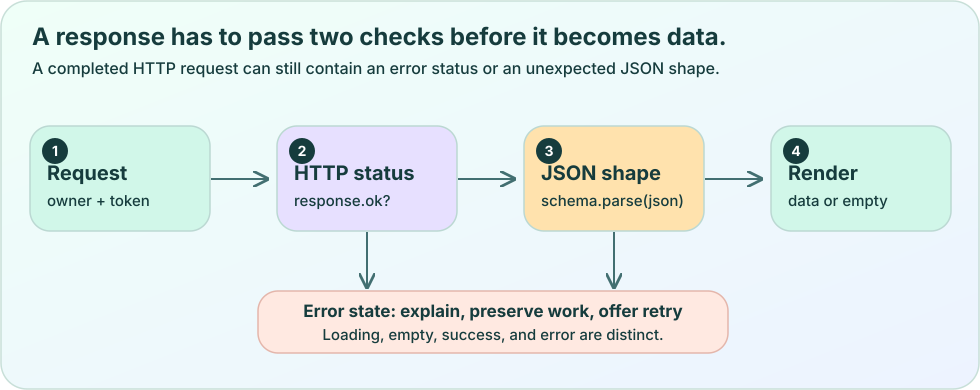

In [2]:
# Embedded original vector illustration; no external image files are required.
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" width="980" height="390" viewBox="0 0 980 390" role="img" aria-labelledby="title desc"><title id="title">Request status and runtime validation</title><desc id="desc">After a request, check HTTP success and then validate the response body. Either check can lead to an error state. Successful empty data is different from a failure.</desc><defs>\n<linearGradient id="bg" x2="1" y2="1"><stop stop-color="#effff8"/><stop offset="1" stop-color="#edf3ff"/></linearGradient>\n<linearGradient id="leaf" x2="1" y2="1"><stop stop-color="#37e6b0"/><stop offset="1" stop-color="#07886c"/></linearGradient>\n<linearGradient id="glass" x2="1" y2="1"><stop stop-color="#fff" stop-opacity=".94"/><stop offset="1" stop-color="#e2efff" stop-opacity=".72"/></linearGradient>\n<linearGradient id="violet" x2="1" y2="1"><stop stop-color="#a58cff"/><stop offset="1" stop-color="#6550d9"/></linearGradient>\n<marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0 0L8 4L0 8" fill="none" stroke="#426f71" stroke-width="1.4"/></marker>\n</defs><g font-family="system-ui,-apple-system,Segoe UI,sans-serif"><rect x="1" y="1" width="978" height="388" rx="26" fill="url(#bg)" stroke="#c8dfd8" stroke-width="1.5"/><text x="32" y="45" font-size="24" fill="#163c3d" font-weight="750" text-anchor="start">A response has to pass two checks before it becomes data.</text><text x="32" y="74" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">A completed HTTP request can still contain an error status or an unexpected JSON shape.</text><rect x="30" y="126" width="180" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="55" cy="151" r="13" fill="#163c3d"/><text x="55" y="156" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">1</text><text x="47" y="180" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Request</text><text x="47" y="206" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">owner + token</text><rect x="277" y="126" width="180" height="105" rx="20" fill="#e7e0ff" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="302" cy="151" r="13" fill="#163c3d"/><text x="302" y="156" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">2</text><text x="294" y="180" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">HTTP status</text><text x="294" y="206" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">response.ok?</text><rect x="524" y="126" width="180" height="105" rx="20" fill="#ffe2ad" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="549" cy="151" r="13" fill="#163c3d"/><text x="549" y="156" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">3</text><text x="541" y="180" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">JSON shape</text><text x="541" y="206" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">schema.parse(json)</text><rect x="771" y="126" width="180" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="796" cy="151" r="13" fill="#163c3d"/><text x="796" y="156" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">4</text><text x="788" y="180" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Render</text><text x="788" y="206" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">data or empty</text><path d="M211 179L267 179" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><path d="M458 179L514 179" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><path d="M705 179L761 179" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><path d="M367 232L367 287" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><path d="M614 232L614 287" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><rect x="258" y="291" width="470" height="62" rx="20" fill="#ffe9e1" stroke="#e4b6ab" stroke-width="1.5"/><text x="493" y="317" font-size="17" fill="#163c3d" font-weight="650" text-anchor="middle">Error state: explain, preserve work, offer retry</text><text x="493" y="340" font-size="15" fill="#163c3d" font-weight="500" text-anchor="middle">Loading, empty, success, and error are distinct.</text></g></svg>'))


**Teaching helper: read-plants.ts**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```ts
import { PlantPage } from "@plantopedia/contracts";

export async function readPlants(
  baseUrl: string, token: string, signal?: AbortSignal,
): Promise<PlantPage> {
  const response = await fetch(`${baseUrl.replace(/\/$/, "")}/v1/plants`, {
    headers: { Authorization: `Bearer ${token}` },
    ...(signal ? { signal } : {}),
  });
  if (!response.ok) throw new Error(`HTTP ${response.status}`);
  const raw: unknown = await response.json();
  return PlantPage.parse(raw);
}
```


## Keep transport and identity in the service layer

The real apiClient in src/services/api.ts performs more work than the teaching helper. It obtains a current token through a callback, uses validated public configuration, checks typed API errors, validates successful responses, and tracks the session’s request lifecycle. Its dispose method aborts requests when that client is released.

Keeping this logic out of each card prevents every screen from inventing slightly different headers and error behavior. The session provider supplies the client for the current owner. The UI asks api.plants() for records rather than reading a credential or constructing a provider request itself.

An owner can be a signed-in cloud account or the app’s local guest owner. The screen can use the same high-level service methods while their available behavior differs. Guest mode is a local experience, not proof that a cloud request has been authenticated. The next lesson examines that authorization boundary in detail.


## Give each result a key that describes all of its identity

TanStack Query keeps results under query keys. Plantopedia’s collection key is [owner, "plants"], and a detail key is [owner, "plant", id]. The owner matters: two accounts can ask for a collection using the same screen component, and those results must not occupy the same cache entry.

A key identifies cached data; it is not a secret and does not authorize a request. The server still verifies the token and checks access. The actual client request also needs lifecycle protection when an account changes. A carefully named cache key cannot stop an already running request on its own.

The QueryClientProvider is already installed in the real root layout. Its defaults retry queries once and consider query data fresh for fifteen seconds. Those are cache freshness and retry choices. They do not mean a result is saved to durable storage, that requests are made every fifteen seconds, or that a lost connection has been repaired.


**Teaching screen excerpt: runs under the existing app providers**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { useQuery } from "@tanstack/react-query";
import { Button, Text, View } from "react-native";
import { useSessionApi } from "../../services/session";

export default function GardenStatus() {
  const { api, owner } = useSessionApi();
  const plants = useQuery({
    queryKey: [owner, "plants"],
    queryFn: () => api.plants(),
  });
  if (!plants.data) {
    if (plants.isPending) return <Text>Loading your garden…</Text>;
    return <View><Text>Your garden could not be loaded.</Text>
      <Button title="Try again" onPress={() => void plants.refetch()} />
    </View>;
  }
  return (
    <View style={{ padding: 24, gap: 12 }}>
      <Text>{plants.data.items.length === 0
        ? "Your garden is empty. Try saving your first plant."
        : `${plants.data.items.length} plants on this page`}</Text>
      {plants.data.items.map(plant =>
        <Text key={plant.id}>{plant.nickname}</Text>)}
      {plants.isFetching && <Text>Checking for updates…</Text>}
      {plants.isError && <Text>Showing saved query data; refresh failed.</Text>}
      <Button title="Refresh" disabled={plants.isFetching}
        onPress={() => void plants.refetch()} />
    </View>
  );
}
```


## Design the four results the reader can actually encounter

Before the first result arrives, show a loading state. If the first request fails and there is no data, show an explanation and an appropriate retry action. If a request succeeds with an empty items array, show an empty collection message. These outcomes have different evidence behind them; an error does not prove the collection is empty.

A later refresh can fail after useful data has already arrived. In that case, keep the known cards visible and explain that checking for updates failed. isFetching can be true during both an initial request and a later refresh. Test data availability separately from refresh activity instead of replacing the whole screen with a spinner every time a request starts.

The example counts records on the returned page. PlantPage includes nextCursor and limited, so a page length is not necessarily the total collection size. In a real growing list, add an explicit pagination or load-more design rather than labeling the first page as the entire garden. Good explanations are precise about both errors and successes.


> **A stale result can still be useful**
>
> Freshness describes whether a cached response may need checking. It does not mean the result is unusable. If a background check fails, show what you know and explain what you could not confirm.


## After a write, decide what is now out of date

A mutation changes server data, such as adding an observation. Once that write succeeds, a previously loaded detail may be out of date. invalidateQueries marks matching cached queries stale and can refetch active ones. Use the same owner and record identity that you used when reading the data.

The real profile screen invalidates [owner, "plant", id] after adding a note. Capture invalidates [owner, "plants"] after saving a specimen. These choices follow the visible information that changed. A mutation does not automatically know every screen that might display a related summary.

Do not retry a write blindly just because the acknowledgement was lost. The server might already have performed it. Plantopedia supplies stable operation keys for such actions; the outbox lesson explains why retrying the same operation differs from starting a new one. Start with honest success and failure handling before adding optimistic updates that temporarily display an unconfirmed change.


**Teaching hook excerpt: invalidate the affected owner and specimen**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { useQueryClient } from "@tanstack/react-query";

export function useRefreshPlant(owner: string, plantId: string) {
  const query = useQueryClient();
  return () => query.invalidateQueries({
    queryKey: [owner, "plant", plantId],
  });
}
```


## Experiment: predict, change, explain

Choose a fixture response scenario and an owner. Predict whether the classifier returns success, empty, or error, and compare the printed query key. Defaults are success and learner_a. This notebook classifies one response at a time; it does not retain a query cache or model a failed background refresh. Use the browser network lab or Expo Query exercise to explore cached data during refresh failures.

The cell below is a bounded Python analogy of the lesson. Its fixtures do not call the app API, request permission, or certify device behavior. Its assertions check the stated model only.


In [3]:
# A deliberately small validator for this notebook's fixture envelope.
# The app uses the richer PlantPage Zod contract.
def inspect_response(status, body):
    if not 200 <= status < 300:
        return 'error', f'HTTP {status}'
    if not isinstance(body, dict) or not isinstance(body.get('items'), list):
        return 'error', 'Invalid response shape'
    if any(not isinstance(p, dict) or not isinstance(p.get('id'), str) or not p['id'] or not isinstance(p.get('nickname'), str) for p in body['items']):
        return 'error', 'Invalid specimen shape'
    return ('success', body['items']) if body['items'] else ('empty', [])

fixtures = {
    'success': (200, {'items': [{'id': 'fern_01', 'nickname': 'Kitchen fern'}]}),
    'empty': (200, {'items': []}),
    'unauthorized': (401, {'code': 'unauthorized'}),
    'unavailable': (503, {'code': 'unavailable'}),
    'malformed': (200, {'items': [{'name': 'missing fields'}]}),
}

def explore_response(scenario='success', owner='learner_a'):
    print('queryKey:', [owner, 'plants'])
    print('Fixture result:', inspect_response(*fixtures[scenario]))
    print('The identity in a cache key is not server authorization.')

explore(explore_response, scenario=list(fixtures), owner=['learner_a', 'learner_b'])
assert inspect_response(*fixtures['empty'])[0] == 'empty'
assert inspect_response(*fixtures['malformed'])[0] == 'error'
assert inspect_response(*fixtures['unauthorized'])[0] == 'error'
assert inspect_response(*fixtures['success'])[0] == 'success'


interactive(children=(Dropdown(description='scenario', options=('success', 'empty', 'unauthorized', 'unavailab…

## Make a prediction of your own

Classify a successful HTTP response whose records have no IDs.

Replace `None` below. A blank answer reports **not attempted**; it is never counted as passing. The check gives feedback without interrupting “Run All.”


In [4]:
your_answer = None  # Replace with inspect_response(200, {'items': [{'nickname': 'Fern'}]})[0].
if your_answer is None:
    print('Not attempted. Replace None, then rerun this cell.')
elif your_answer == 'error':
    print('Correct. '+'Successful transport does not validate JSON. Reject the malformed record before caching it.')
else:
    print('Revisit your prediction. '+'Successful transport does not validate JSON. Reject the malformed record before caching it.')


Not attempted. Replace None, then rerun this cell.


## Retrieve the ideas

**1. fetch receives an HTTP 500 response. Which check is still necessary?**

1. response.ok, because HTTP error responses do not normally reject fetch by themselves.
2. Only whether the URL contains https.
3. Only whether TypeScript accepted the return type.

**2. A refresh fails, but the query still has a previously loaded page. What should the screen usually do?**

1. Announce that the garden is empty.
2. Keep useful records visible and explain that the refresh failed.
3. Delete all cached records immediately.

**3. Why include owner in [owner, "plant", id]?**

1. It encrypts the plant ID.
2. It replaces token validation on the server.
3. It separates account-specific cache entries.

Set each value in the next cell to your selected option number, starting at 1. You can change it and rerun for more feedback.


In [5]:
quiz = [{'question': 'fetch receives an HTTP 500 response. Which check is still necessary?', 'options': ['response.ok, because HTTP error responses do not normally reject fetch by themselves.', 'Only whether the URL contains https.', 'Only whether TypeScript accepted the return type.'], 'answer': 0, 'explanation': 'fetch can resolve with an error-status Response. Inspect status or ok before parsing the success contract. HTTPS and static types solve different problems.'}, {'question': 'A refresh fails, but the query still has a previously loaded page. What should the screen usually do?', 'options': ['Announce that the garden is empty.', 'Keep useful records visible and explain that the refresh failed.', 'Delete all cached records immediately.'], 'answer': 1, 'explanation': 'The failure tells you that the latest check did not succeed. It does not prove the existing records disappeared. Distinguish stale available data from an initial failure with no data.'}, {'question': 'Why include owner in [owner, "plant", id]?', 'options': ['It encrypts the plant ID.', 'It replaces token validation on the server.', 'It separates account-specific cache entries.'], 'answer': 2, 'explanation': 'The cache key describes which owner’s result is stored. Server authentication and authorization remain necessary. A key also does not automatically cancel an in-flight request.'}]
answers = [None, None, None]  # Replace None with 1, 2, or 3.
correct = 0
for number, (question, answer) in enumerate(zip(quiz, answers), 1):
    if answer is None:
        print(f'{number}. Not attempted.')
    elif type(answer) is not int or answer not in range(1, len(question['options']) + 1):
        print(f'{number}. Choose a valid option number.')
    else:
        right = answer - 1 == question['answer']
        correct += int(right)
        print(f"{number}. {'Correct' if right else 'Revisit this idea'}. {question['explanation']}")
print(f'{correct} of {len(quiz)} correct; unanswered questions do not count as passing.')


1. Not attempted.
2. Not attempted.
3. Not attempted.
0 of 3 correct; unanswered questions do not count as passing.


## Build in Expo: Build a truthful garden status screen

Use a deterministic teaching transport or the provided network lab to cover the outcomes before connecting a learning screen to the real session API.

1. List the result of network rejection, HTTP 401, HTTP 500, invalid JSON shape, empty success, and populated success.
2. Implement the no-data loading, no-data failure, empty success, and populated-data branches.
3. Retain the populated branch during a later refresh and show a separate refresh failure message.
4. Use [owner, "plants"] for the collection and [owner, "plant", id] for a detail.
5. After a successful note write, invalidate the affected detail key. Explain separately how a stable operation key makes a retry safer.
6. Record whether the displayed count describes one page or the entire collection.

### Check your result

- [ ] An HTTP error is not mistaken for a successful response.
- [ ] Malformed data is rejected before rendering as a valid PlantPage.
- [ ] An empty success and an initial failure have different messages.
- [ ] Cached cards remain visible during a failed refresh.
- [ ] Account identity is present in every private-record query key.

Download the matching exercise bundle from the HTML course, or use the `exercises` folder if you downloaded the complete course. A notebooks-only download does not include that folder. Files under `docs/tutorials` do not become Expo routes until copied as instructed. The numbered workbook supplies a related concrete practice task; the inline exercise can ask you to extend it.


<details><summary>Hint</summary>

Check whether data exists before deciding that an error must replace the entire screen. Query freshness, data presence, and request activity are separate facts.

</details>

<details><summary>Worked reasoning / solution</summary>

```text
Use the GardenStatus branching structure. The transport checks response.ok, then parses unknown JSON with PlantPage. For private cloud reads, the session API supplies the current token and request lifecycle. A successful mutation can return query.invalidateQueries({queryKey:[owner,"plant",id]}). Keep the page visible when data exists, and use isFetching or isError for a separate update message. The existing api.plants wrapper does not consume TanStack’s signal argument, so do not claim that merely unmounting this teaching screen cancels that request; the real client’s lifecycle abort is separate.
```

</details>


## Explain it in your own words

The app shows three cached plants while a refresh receives 401. Explain what the UI knows, what it does not know, and why fixing the query key cannot repair an expired or mismatched session.

*Write your explanation in the Markdown cell below. Save the notebook to keep your work.*


My explanation:

<!-- Replace this comment with a connected explanation and an example. -->


## Find this idea in the app

- [src/services/api.ts](../../../src/services/api.ts) — Implements authenticated requests, typed errors, response validation, and session lifecycle cancellation.

- [src/services/session.tsx](../../../src/services/session.tsx) — Creates the current owner’s service scope and releases it on lifecycle changes.

- [src/app/(tabs)/explore.tsx](../../../src/app/(tabs)/explore.tsx) — Reads the owner-scoped collection and distinguishes initial, cached, and refresh states.

- [src/app/plants/[plantId].tsx](../../../src/app/plants/[plantId].tsx) — Loads owner-scoped detail, caches it locally, and invalidates it after a successful observation write.

- [src/app/_layout.tsx](../../../src/app/_layout.tsx) — Defines the stable QueryClient with this repository’s retry and freshness defaults.

Repository links require this notebook to remain in the checkout’s `docs/tutorials/notebooks` folder. Downloaded notebooks still contain every explanation and embedded diagram.

## Primary documentation

- [React Native networking](https://reactnative.dev/docs/network)
- [TanStack Query keys](https://tanstack.com/query/latest/docs/framework/react/guides/query-keys)
- [TanStack query invalidation](https://tanstack.com/query/latest/docs/framework/react/guides/query-invalidation)
- [TanStack background fetching indicators](https://tanstack.com/query/latest/docs/framework/react/guides/background-fetching-indicators)


## Carry these ideas forward

- A reliable request checks connectivity, HTTP status, parsing, and response shape.
- Query keys identify cached results, while the server authorizes access.
- Data availability, request activity, and freshness deserve separate UI decisions.
